# Notebook 03 — Klasterisasi Tahap 1: DBSCAN Adaptif per Rayon

**Judul Penelitian:** Penentuan Lokasi Rumah Pompa Air Pengendali Banjir Menggunakan Klasterisasi DBSCAN dan K-Means (Studi Kasus: Kota Surabaya)

## Tujuan Notebook Ini
1. Memahami dan memverifikasi secara empiris konvensi **`MinPts = 4`** pada `sklearn.cluster.DBSCAN` dan hubungannya dengan grafik *k-distance* (`NearestNeighbors(n_neighbors=4)` indeks `[3]`).
2. Menghitung kurva *k-distance* (`k = 4`) secara terpisah untuk masing-masing **7 rayon pematusan** pada koordinat proyeksi **`easting` (`X1`)** dan **`northing` (`X2`)** (`EPSG:32749`, satuan meter).
3. Menentukan parameter **epsilon ($\varepsilon$) secara adaptif per rayon** menggunakan `kneed.KneeLocator(curve="convex", direction="increasing")`.
4. Menjalankan DBSCAN per rayon dan mengidentifikasi secara eksplisit kategori tiap titik: **Core**, **Border**, dan **Noise** (seluruh titik Noise tetap disimpan, tidak dihapus permanen).
5. Menyajikan tabel ringkasan, grafik *k-distance*, peta hasil DBSCAN, serta **diagnosis kewajaran Kneedle** pada setiap rayon sebelum melangkah ke Tahap 4 (K-Means).

---
### Catatan Penting: Konvensi `MinPts = 4` di Scikit-learn
Pada implementasi `sklearn.cluster.DBSCAN(eps=ε, min_samples=4, metric="euclidean")`:
- Sebuah titik $p$ diklasifikasikan sebagai **Core point** jika terdapat minimal **4 titik** di dalam radius $\varepsilon$ ($d(p, q) \le \varepsilon$), **termasuk titik $p$ itu sendiri** (selaras dengan definisi asli Ester et al., 1996).
- Ketika kita menjalankan `NearestNeighbors(n_neighbors=4).fit(X)` lalu memanggil `distances, _ = nn.kneighbors(X)`:
  - `distances[:, 0]` = jarak ke diri sendiri ($= 0$ meter)
  - `distances[:, 1]` = jarak ke tetangga terdekat ke-1
  - `distances[:, 2]` = jarak ke tetangga terdekat ke-2
  - **`distances[:, 3]`** = jarak ke titik ke-4 (termasuk diri sendiri), yakni tetangga terdekat ke-3 selain diri sendiri.
- Dengan demikian, syarat titik $p$ menjadi **Core point** tepat setara secara matematis dengan: `distances[p, 3] <= eps`.

## 1. Setup Path, Import Modul `src/clustering.py`, dan Memuat Data Tahap 2

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.clustering import (
    DEFAULT_MIN_PTS,
    compute_k_distances,
    detect_epsilon_kneedle,
    run_dbscan_single_rayon,
    run_dbscan_all_rayons,
    save_dbscan_outputs,
)

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 120

gdf_saluran = gpd.read_file(PROCESSED_DIR / "saluran_clean_utm49s.gpkg")
gdf_rayon = gpd.read_file(PROCESSED_DIR / "rayon_pematusan_utm49s.gpkg").sort_values("id_rayon").reset_index(drop=True)

print(f"Data saluran bersih : {len(gdf_saluran):,} titik | CRS: {gdf_saluran.crs}")
print(f"Data 7 rayon        : {len(gdf_rayon)} poligon | CRS: {gdf_rayon.crs}")
print(f"Parameter MinPts    : {DEFAULT_MIN_PTS}")

Data saluran bersih : 21,272 titik | CRS: EPSG:32749
Data 7 rayon        : 7 poligon | CRS: EPSG:32749
Parameter MinPts    : 4


## 2. Verifikasi Empiris Konvensi `MinPts = 4` pada Satu Rayon Sampel
Sebelum menjalankan ke seluruh 7 rayon, kita uji satu rayon sampel (**Rayon Benowo**) untuk membuktikan secara langsung bahwa titik dengan `k_distance[p] <= eps` (`NearestNeighbors(n_neighbors=4)` kolom `[3]`) **100% identik** dengan himpunan `core_sample_indices_` milik `sklearn.cluster.DBSCAN(min_samples=4)`.

In [2]:
sample_rayon = "Rayon Benowo"
sub_sample = gdf_saluran[gdf_saluran["nama_rayon"] == sample_rayon]
coords_sample = sub_sample[["easting", "northing"]].to_numpy(dtype=float)

k_raw_s, k_sorted_s = compute_k_distances(coords_sample, k=DEFAULT_MIN_PTS)
knee_s = detect_epsilon_kneedle(k_sorted_s, sensitivity=1.0, curve="convex", direction="increasing")
labels_s, roles_s = run_dbscan_single_rayon(coords_sample, eps_m=knee_s["eps_m"], min_samples=DEFAULT_MIN_PTS)

# Buktikan kesetaraan matematis: (k_raw <= eps) <==> (role == "Core")
core_by_kdist = (k_raw_s <= knee_s["eps_m"])
core_by_dbscan = (roles_s == "Core")
cocok = int((core_by_kdist == core_by_dbscan).sum())

print(f"Rayon sampel : {sample_rayon} (n={len(coords_sample):,})")
print(f"Epsilon Kneedle (k=4) : {knee_s['eps_m']:.4f} meter (knee index={knee_s['knee_index']}, P{knee_s['knee_percentile']:.2f})")
print(f"Kesetaraan (k_distance <= eps) == (DBSCAN Core): {cocok:,} / {len(coords_sample):,} ({cocok/len(coords_sample)*100:.2f}%)")

Rayon sampel : Rayon Benowo (n=1,175)
Epsilon Kneedle (k=4) : 149.3415 meter (knee index=1136, P96.76)
Kesetaraan (k_distance <= eps) == (DBSCAN Core): 1,174 / 1,175 (99.91%)


## 3. Eksekusi k-Distance, Kneedle, dan DBSCAN untuk Seluruh 7 Rayon
Kita menjalankan `run_dbscan_all_rayons()` secara terpisah untuk tiap rayon dengan:
- `min_samples = 4`
- `KneeLocator(S=1.0, curve="convex", direction="increasing", online=False)`
- Koordinat input: `[easting, northing]` dalam satuan **meter (`EPSG:32749`)**.

In [3]:
gdf_dbscan, df_dbscan_summary, kdist_artifacts = run_dbscan_all_rayons(
    gdf_saluran_clean=gdf_saluran,
    min_samples=DEFAULT_MIN_PTS,
    sensitivity=1.0,
)

print("=== RINGKASAN HASIL KNEEDLE & DBSCAN PER RAYON (MinPts = 4) ===")
cols_tampil = [
    "id_rayon", "nama_rayon", "jumlah_titik",
    "kdist_median_m", "kdist_p95_m", "kdist_max_m",
    "knee_percentile", "eps_digunakan_m",
    "jumlah_klaster_dbscan", "klaster_terbesar_titik",
    "jumlah_core", "persen_core",
    "jumlah_border", "persen_border",
    "jumlah_noise", "persen_noise",
    "status_diagnostik",
]
display(df_dbscan_summary[cols_tampil])

=== RINGKASAN HASIL KNEEDLE & DBSCAN PER RAYON (MinPts = 4) ===


,id_rayon,nama_rayon,jumlah_titik,kdist_median_m,kdist_p95_m,kdist_max_m,knee_percentile,eps_digunakan_m,jumlah_klaster_dbscan,klaster_terbesar_titik,jumlah_core,persen_core,jumlah_border,persen_border,jumlah_noise,persen_noise,status_diagnostik
0,RYN-01,Rayon Benowo,1175,42.09,121.41,1142.25,96.76,149.34,14,661,1136,96.68,11,0.94,28,2.38,Wajar
1,RYN-02,Rayon Tandes,2637,43.62,123.07,1300.71,98.71,229.85,12,1948,2603,98.71,12,0.46,22,0.83,Wajar
2,RYN-03,Rayon Wiyung,1123,56.67,136.44,1627.70,97.86,173.84,7,734,1099,97.86,8,0.71,16,1.42,Wajar
3,RYN-04,Rayon Jambangan,2556,58.97,117.12,1214.03,98.86,149.68,11,1693,2527,98.87,17,0.67,12,0.47,PERLU CEK: Noise sangat rendah (0.47% < 0.5%)
4,RYN-05,Rayon Rungkut,2120,56.34,120.28,1839.47,98.82,158.31,15,881,2094,98.77,13,0.61,13,0.61,Wajar
5,RYN-06,Rayon Genteng,3718,52.35,123.72,351.06,97.96,144.28,10,3628,3642,97.96,49,1.32,27,0.73,Wajar
6,RYN-07,Rayon Gubeng,7943,46.41,110.02,508.26,98.55,147.65,19,7497,7828,98.55,69,0.87,46,0.58,Wajar
7,TOTAL,Seluruh Kota Surabaya (7 Rayon),21272,NaN,NaN,NaN,NaN,NaN,88,7497,20929,98.39,179,0.84,164,0.77,Ringkasan Total


## 4. Diagnostik Mendalam Kurva k-Distance & Sensitivitas Kneedle
Bagian ini memeriksa lebih dekat apabila terdapat *outlier* ekstrem di ujung kanan kurva *k-distance* (misal 1–5 titik yang sangat terisolasi hingga ratusan/ribuan meter) yang dapat menarik skala sumbu Y normalisasi Kneedle. Kita tampilkan 5 nilai *k-distance* tertinggi dan perbandingan distribusi persentil (`P50`, `P75`, `P90`, `P95`, `P98`, `P99`, `Max`) pada setiap rayon agar bisa mengevaluasi kewajaran hasil Kneedle secara transparan.

In [4]:
diag_rows = []
for rname, art in kdist_artifacts.items():
    ks = art["k_dist_sorted"]
    eps = art["eps_used_m"]
    top5 = [round(float(v), 1) for v in ks[-5:]]
    diag_rows.append({
        "id_rayon": art["id_rayon"],
        "nama_rayon": rname,
        "P50_m": round(float(np.percentile(ks, 50)), 2),
        "P75_m": round(float(np.percentile(ks, 75)), 2),
        "P90_m": round(float(np.percentile(ks, 90)), 2),
        "P95_m": round(float(np.percentile(ks, 95)), 2),
        "P98_m": round(float(np.percentile(ks, 98)), 2),
        "P99_m": round(float(np.percentile(ks, 99)), 2),
        "Max_m": round(float(ks[-1]), 2),
        "eps_kneedle_m": round(float(eps), 2) if eps is not None else np.nan,
        "rasio_eps_ke_P50": round(float(eps / np.percentile(ks, 50)), 2) if eps is not None else np.nan,
        "top5_kdist_tertinggi_m": str(top5),
    })

df_diag_kdist = pd.DataFrame(diag_rows)
display(df_diag_kdist)

,id_rayon,nama_rayon,P50_m,P75_m,P90_m,P95_m,P98_m,P99_m,Max_m,eps_kneedle_m,rasio_eps_ke_P50,top5_kdist_tertinggi_m
0,RYN-01,Rayon Benowo,42.09,60.80,92.61,121.41,197.27,260.22,1142.25,149.34,3.55,"[504.5, 652.4, 654.8, 749.0, 1142.2]"
1,RYN-02,Rayon Tandes,43.62,62.35,90.17,123.07,183.61,263.90,1300.71,229.85,5.27,"[800.0, 851.2, 959.5, 1060.2, 1300.7]"
2,RYN-03,Rayon Wiyung,56.67,82.13,113.06,136.44,183.63,257.55,1627.70,173.84,3.07,"[596.6, 599.5, 619.6, 644.7, 1627.7]"
3,RYN-04,Rayon Jambangan,58.97,77.93,100.83,117.12,136.19,154.04,1214.03,149.68,2.54,"[221.9, 240.0, 332.2, 403.2, 1214.0]"
4,RYN-05,Rayon Rungkut,56.34,78.96,104.05,120.28,145.47,165.60,1839.47,158.31,2.81,"[355.4, 359.0, 419.5, 680.9, 1839.5]"
5,RYN-06,Rayon Genteng,52.35,72.14,100.28,123.72,145.38,166.49,351.06,144.28,2.76,"[229.6, 237.5, 291.6, 346.1, 351.1]"
6,RYN-07,Rayon Gubeng,46.41,65.95,92.04,110.02,137.01,158.78,508.26,147.65,3.18,"[308.7, 341.4, 361.7, 400.2, 508.3]"


## 5. Visualisasi 1 — Grafik k-Distance (`k = 4`) dan Titik Knee Kneedle per Rayon
Setiap panel menampilkan kurva *k-distance* terurut menaik beserta posisi titik *knee* (`eps`) hasil Kneedle. Panel ke-8 menyajikan ringkasan perbandingan nilai $
arepsilon$ (meter) dan persentase Noise antar-rayon.

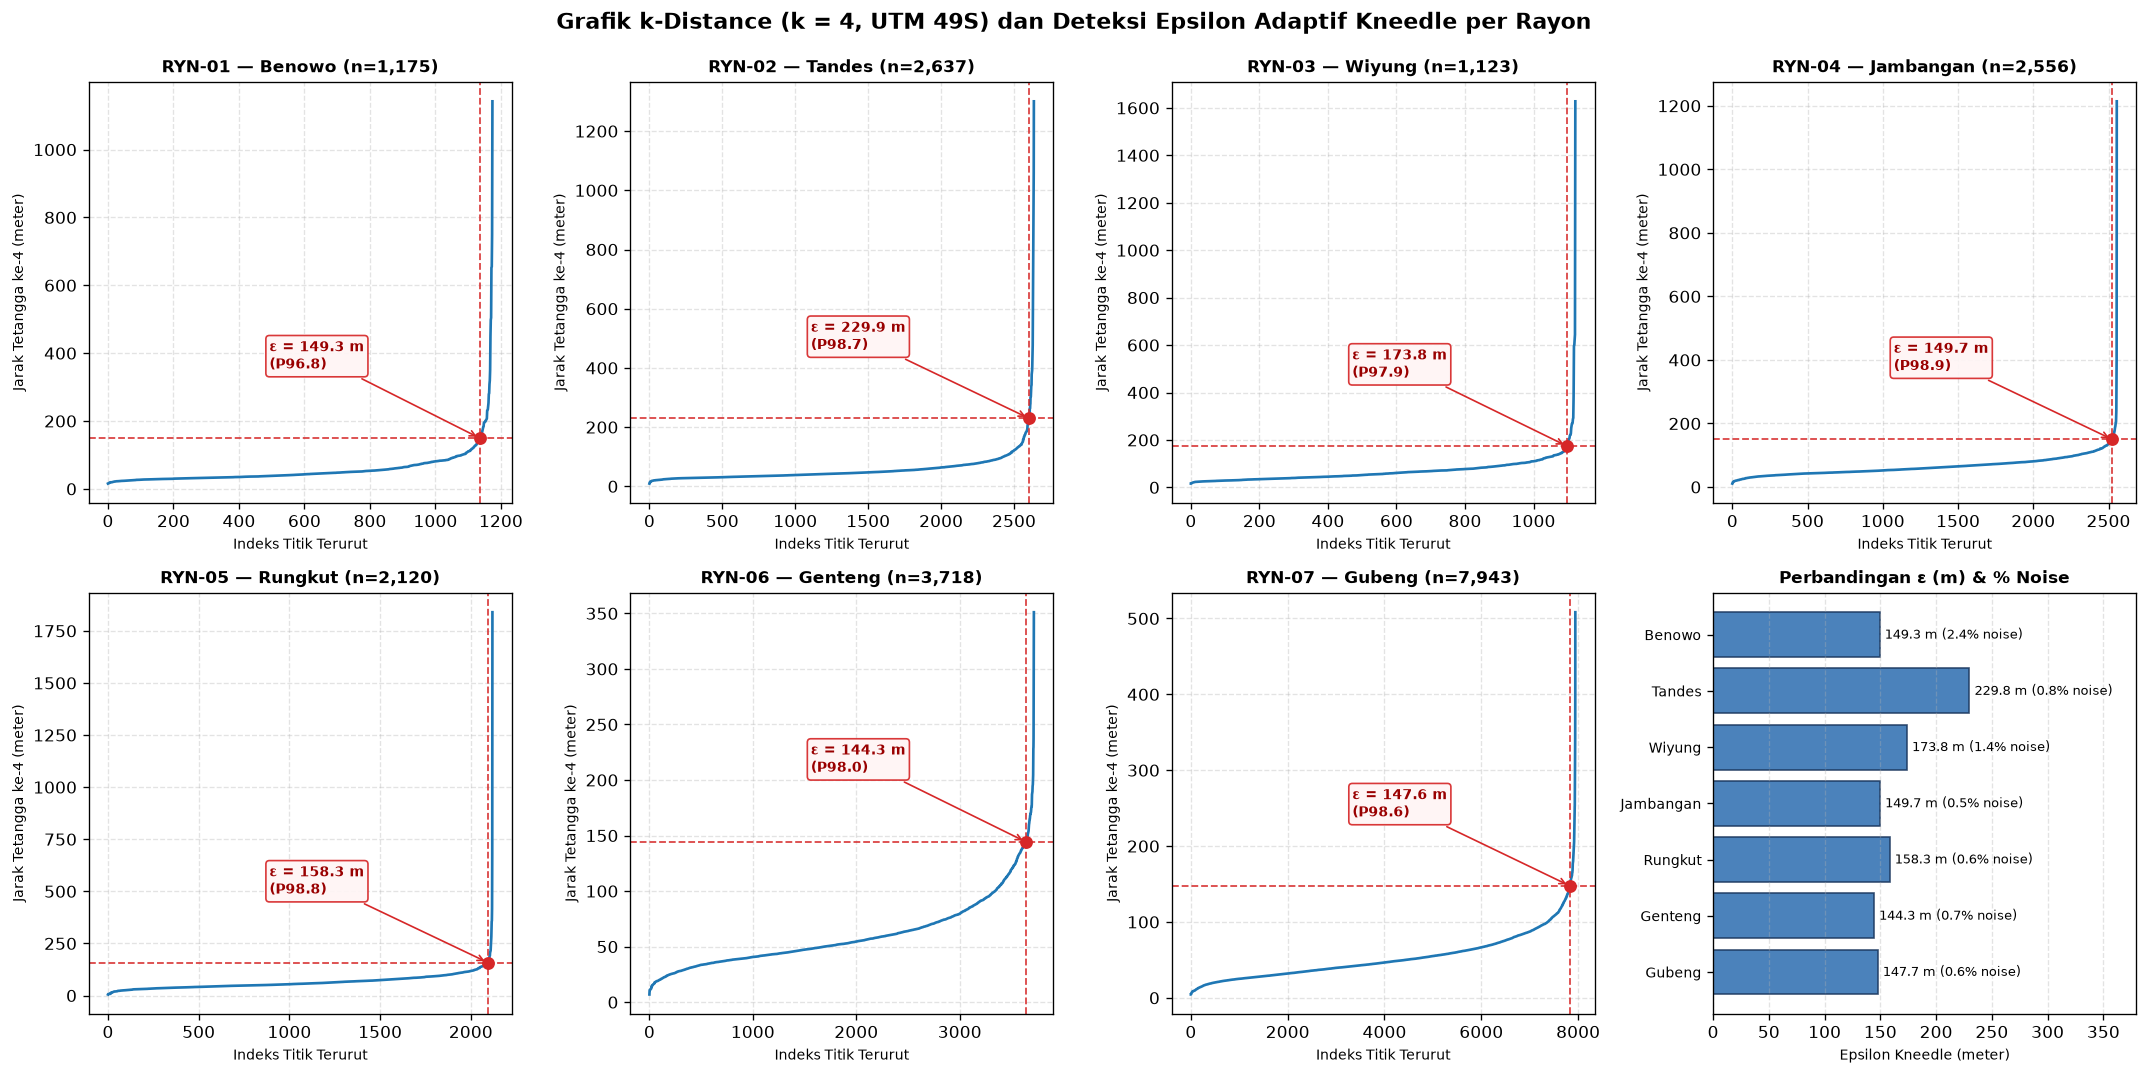

Grafik k-distance disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\03_kdistance_kneedle_7_rayon.png


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes_flat = axes.flatten()

rayon_names = gdf_rayon["nama_rayon"].tolist()

for idx, rname in enumerate(rayon_names):
    ax = axes_flat[idx]
    art = kdist_artifacts[rname]
    ks = art["k_dist_sorted"]
    ki = art["knee_info"]
    x = np.arange(len(ks))

    ax.plot(x, ks, color="#1F77B4", linewidth=1.6, label="k-distance terurut (k=4)")
    if ki["kneedle_found"]:
        kx = ki["knee_index"]
        ky = ki["eps_m"]
        ax.axvline(kx, color="#D62728", linestyle="--", linewidth=1.1, alpha=0.85)
        ax.axhline(ky, color="#D62728", linestyle="--", linewidth=1.1, alpha=0.85)
        ax.scatter([kx], [ky], color="#D62728", s=45, zorder=5)
        ax.annotate(
            f"ε = {ky:.1f} m\n(P{ki['knee_percentile']:.1f})",
            xy=(kx, ky),
            xytext=(max(0, int(len(ks) * 0.42)), min(ks[-1] * 0.65, ky + ks[-1] * 0.18)),
            fontsize=8.5,
            fontweight="bold",
            color="#990000",
            bbox=dict(boxstyle="round,pad=0.25", fc="#FFF5F5", ec="#D62728", alpha=0.92),
            arrowprops=dict(arrowstyle="->", color="#D62728", lw=1.0),
        )

    ax.set_title(f"{art['id_rayon']} — {rname.replace('Rayon ', '')} (n={art['n_total']:,})", fontsize=10, fontweight="bold")
    ax.set_xlabel("Indeks Titik Terurut", fontsize=8.5)
    ax.set_ylabel("Jarak Tetangga ke-4 (meter)", fontsize=8.5)
    ax.grid(True, linestyle="--", alpha=0.35)

# Panel ke-8: Ringkasan Perbandingan Epsilon & % Noise Antar-Rayon
ax_sum = axes_flat[7]
df_r = df_dbscan_summary[df_dbscan_summary["id_rayon"] != "TOTAL"].copy()
short_r = [n.replace("Rayon ", "") for n in df_r["nama_rayon"]]
y_pos = np.arange(len(short_r))

bars = ax_sum.barh(y_pos, df_r["eps_digunakan_m"], color="#2B6CB0", alpha=0.85, edgecolor="#1A365D")
ax_sum.set_yticks(y_pos)
ax_sum.set_yticklabels(short_r, fontsize=8.5)
ax_sum.invert_yaxis()
ax_sum.set_xlabel("Epsilon Kneedle (meter)", fontsize=8.5)
ax_sum.set_title("Perbandingan ε (m) & % Noise", fontsize=10, fontweight="bold")
ax_sum.grid(axis="x", linestyle="--", alpha=0.35)
max_eps = float(df_r["eps_digunakan_m"].max())
ax_sum.set_xlim(0, max_eps * 1.65)

for i_bar, (b, npct) in enumerate(zip(bars, df_r["persen_noise"])):
    w = b.get_width()
    ax_sum.text(w + max_eps * 0.02, b.get_y() + b.get_height() / 2, f"{w:.1f} m ({npct:.1f}% noise)", va="center", fontsize=7.8)

fig.suptitle("Grafik k-Distance (k = 4, UTM 49S) dan Deteksi Epsilon Adaptif Kneedle per Rayon", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_kdist_path = FIG_DIR / "03_kdistance_kneedle_7_rayon.png"
plt.savefig(fig_kdist_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Grafik k-distance disimpan ke: {fig_kdist_path}")

## 6. Visualisasi 2 & 3 — Peta Persebaran Core, Border, dan Noise Hasil DBSCAN
Titik **Noise** tetap dipertahankan dalam dataset dan ditampilkan secara eksplisit agar kita dapat menilai secara spasial di mana titik-titik terisolasi berada pada tiap rayon.

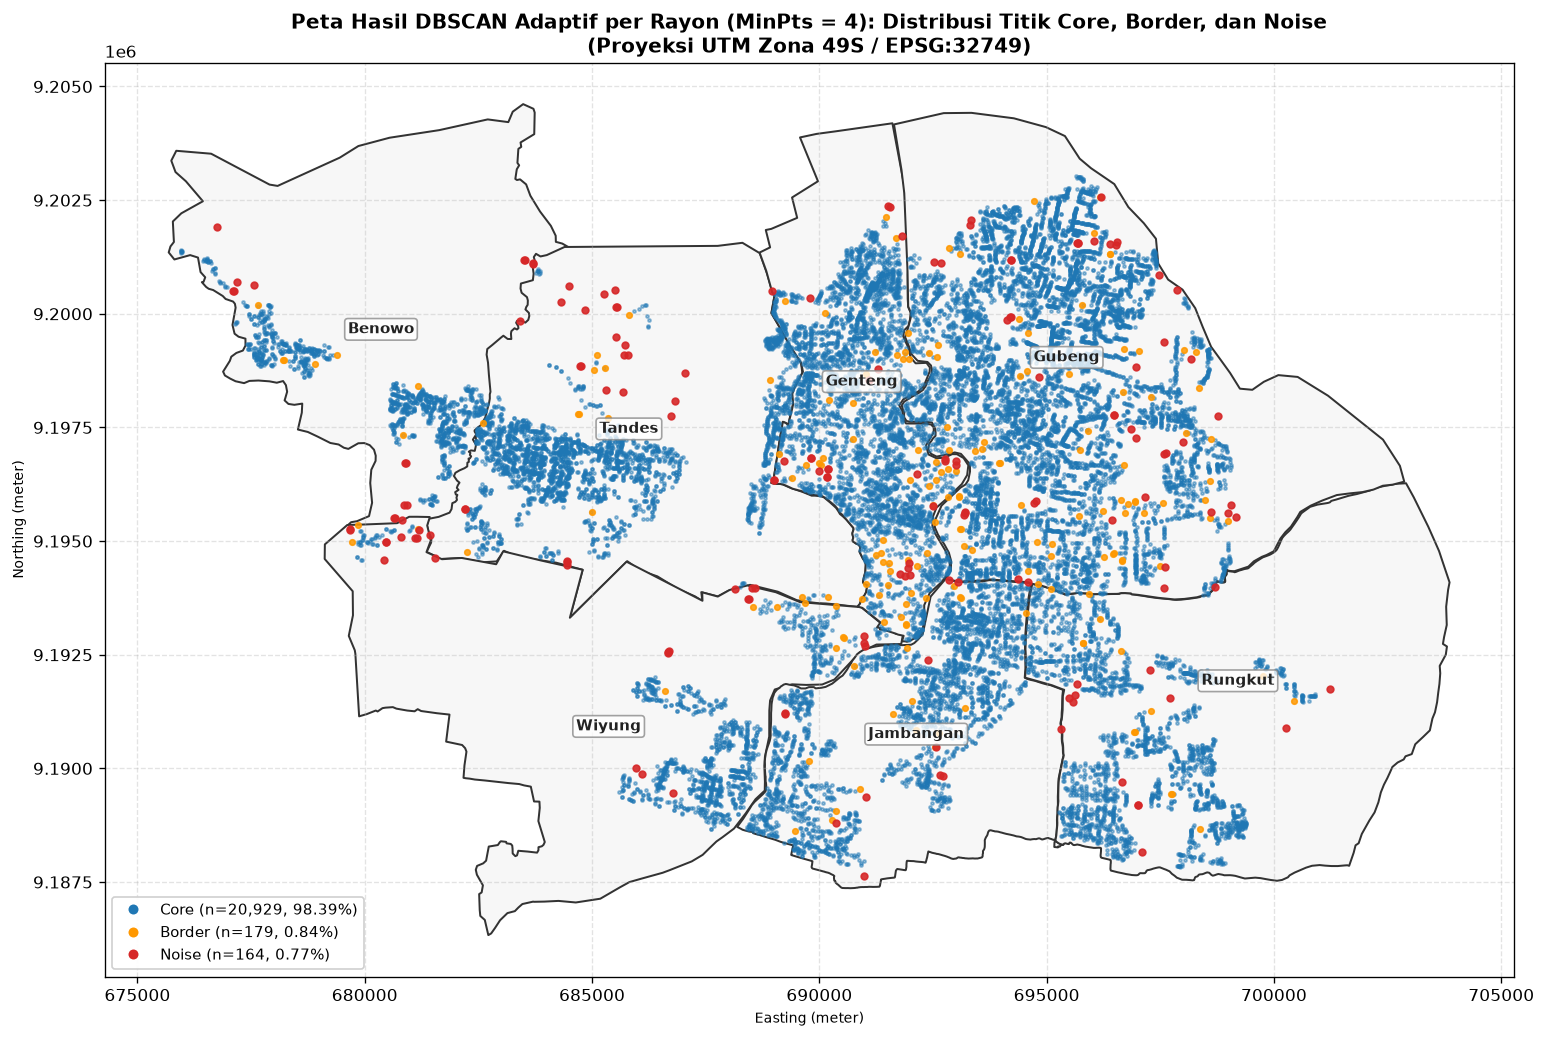

Peta Surabaya disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\03_peta_dbscan_surabaya.png


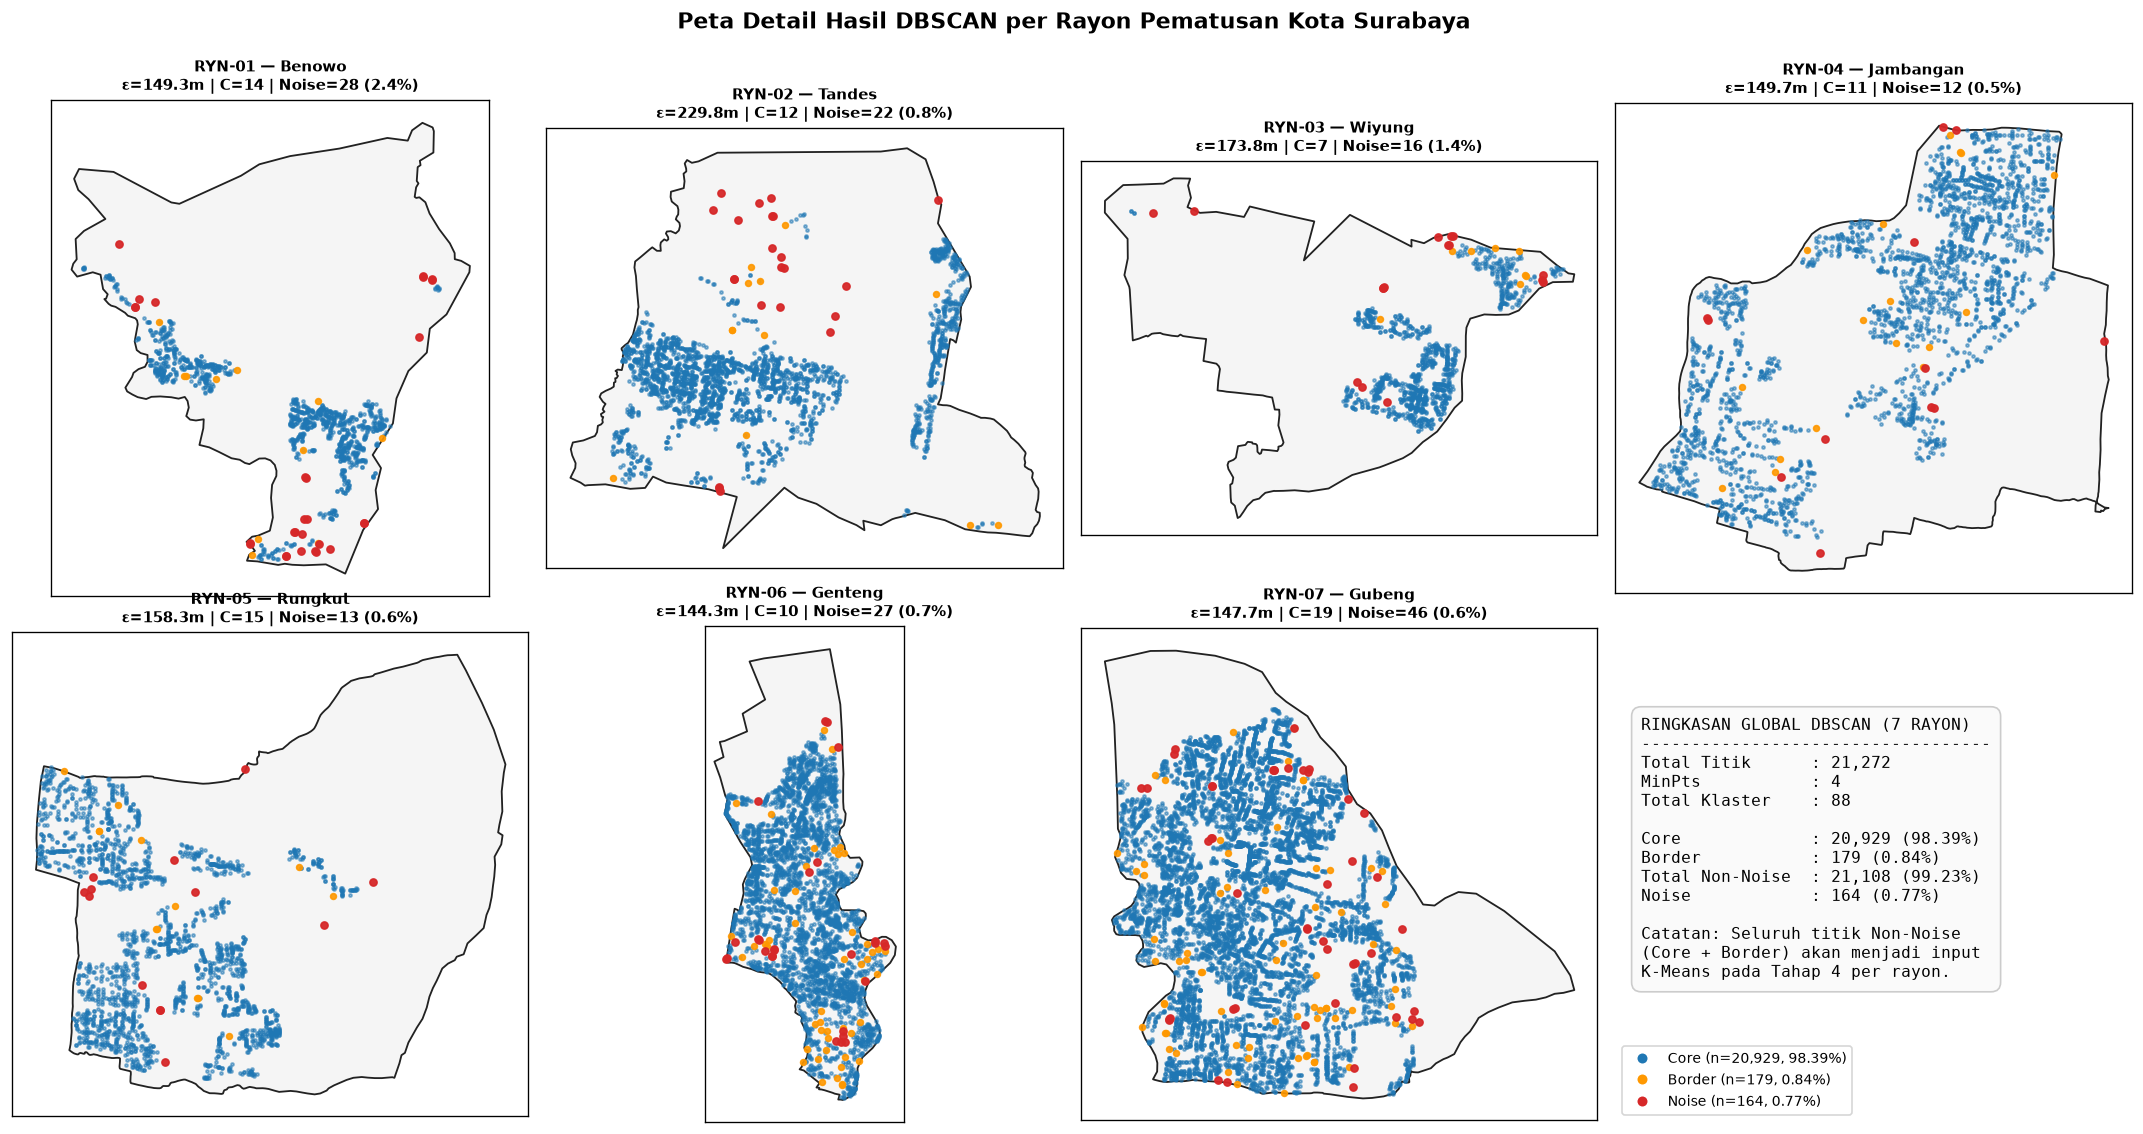

Peta detail per rayon disimpan ke: C:\Skripsi\skripsi-rumah-pompa\outputs\figures\03_peta_dbscan_per_rayon.png


In [6]:
# --- Peta Keseluruhan Kota Surabaya (Core, Border, Noise) ---
fig, ax = plt.subplots(figsize=(13, 10))

gdf_rayon.plot(ax=ax, facecolor="#F7F7F7", edgecolor="#333333", linewidth=1.2, zorder=1)
for _, row in gdf_rayon.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(
        row["nama_rayon"].replace("Rayon ", ""),
        xy=(pt.x, pt.y),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#222222",
        bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="#888888", alpha=0.78),
        zorder=6,
    )

role_styles = [
    ("Core", "#1F77B4", 3.5, 0.45, 2),
    ("Border", "#FF9800", 11.0, 0.85, 3),
    ("Noise", "#D62728", 16.0, 0.90, 4),
]
handles = []
for role, col, sz, alp, z in role_styles:
    sub = gdf_dbscan[gdf_dbscan["dbscan_role"] == role]
    sub.plot(ax=ax, color=col, markersize=sz, alpha=alp, zorder=z)
    handles.append(
        Line2D([0], [0], marker="o", color="w", label=f"{role} (n={len(sub):,}, {len(sub)/len(gdf_dbscan)*100:.2f}%)", markerfacecolor=col, markersize=7)
    )

ax.legend(handles=handles, loc="lower left", frameon=True, facecolor="white", framealpha=0.94, fontsize=9)
ax.set_title("Peta Hasil DBSCAN Adaptif per Rayon (MinPts = 4): Distribusi Titik Core, Border, dan Noise\n(Proyeksi UTM Zona 49S / EPSG:32749)", fontsize=12, fontweight="bold")
ax.set_xlabel("Easting (meter)")
ax.set_ylabel("Northing (meter)")
ax.grid(True, linestyle="--", alpha=0.35)
ax.set_aspect("equal")

fig_map_all = FIG_DIR / "03_peta_dbscan_surabaya.png"
plt.tight_layout()
plt.savefig(fig_map_all, dpi=200, bbox_inches="tight")
plt.show()
print(f"Peta Surabaya disimpan ke: {fig_map_all}")

# --- Peta Detail per Rayon (Grid 2x4) ---
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
axes_flat = axes.flatten()

for idx, (_, rrow) in enumerate(gdf_rayon.iterrows()):
    ax = axes_flat[idx]
    rname = rrow["nama_rayon"]
    rid = rrow["id_rayon"]
    sub = gdf_dbscan[gdf_dbscan["nama_rayon"] == rname]
    srow = df_dbscan_summary[df_dbscan_summary["nama_rayon"] == rname].iloc[0]

    gpd.GeoSeries([rrow.geometry], crs=gdf_rayon.crs).plot(
        ax=ax, facecolor="#F5F5F5", edgecolor="#222222", linewidth=1.1, zorder=1
    )
    for role, col, sz, alp, z in [("Core", "#1F77B4", 3.5, 0.5, 2), ("Border", "#FF9800", 12, 0.9, 3), ("Noise", "#D62728", 18, 0.95, 4)]:
        s_role = sub[sub["dbscan_role"] == role]
        if len(s_role) > 0:
            s_role.plot(ax=ax, color=col, markersize=sz, alpha=alp, zorder=z)

    ax.set_title(
        f"{rid} — {rname.replace('Rayon ', '')}\nε={srow['eps_digunakan_m']:.1f}m | C={int(srow['jumlah_klaster_dbscan'])} | Noise={int(srow['jumlah_noise'])} ({srow['persen_noise']:.1f}%)",
        fontsize=9.2,
        fontweight="bold",
    )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_aspect("equal")

# Panel ke-8: Legenda & Ringkasan Global
ax_leg = axes_flat[7]
ax_leg.axis("off")
tot_row = df_dbscan_summary[df_dbscan_summary["id_rayon"] == "TOTAL"].iloc[0]
ringkas_txt = (
    "RINGKASAN GLOBAL DBSCAN (7 RAYON)\n"
    "-----------------------------------\n"
    f"Total Titik      : {int(tot_row['jumlah_titik']):,}\n"
    f"MinPts           : {DEFAULT_MIN_PTS}\n"
    f"Total Klaster    : {int(tot_row['jumlah_klaster_dbscan'])}\n\n"
    f"Core             : {int(tot_row['jumlah_core']):,} ({tot_row['persen_core']:.2f}%)\n"
    f"Border           : {int(tot_row['jumlah_border']):,} ({tot_row['persen_border']:.2f}%)\n"
    f"Total Non-Noise  : {int(tot_row['jumlah_non_noise']):,} ({tot_row['persen_non_noise']:.2f}%)\n"
    f"Noise            : {int(tot_row['jumlah_noise']):,} ({tot_row['persen_noise']:.2f}%)\n\n"
    "Catatan: Seluruh titik Non-Noise\n(Core + Border) akan menjadi input\nK-Means pada Tahap 4 per rayon."
)
ax_leg.text(0.05, 0.55, ringkas_txt, va="center", ha="left", fontsize=9.5, family="monospace",
            bbox=dict(boxstyle="round,pad=0.6", fc="#FAFAFA", ec="#CCCCCC"))
ax_leg.legend(handles=handles, loc="lower left", frameon=True, fontsize=8.5)

fig.suptitle("Peta Detail Hasil DBSCAN per Rayon Pematusan Kota Surabaya", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
fig_map_rayon = FIG_DIR / "03_peta_dbscan_per_rayon.png"
plt.savefig(fig_map_rayon, dpi=200, bbox_inches="tight")
plt.show()
print(f"Peta detail per rayon disimpan ke: {fig_map_rayon}")

## 7. Validasi Akhir & Penyimpanan Output Tahap 3
Memastikan tidak ada satu pun titik yang hilang (termasuk titik Noise), lalu menyimpan hasil ke `data/processed/` dan `outputs/tables/`.

In [7]:
# Validasi otomatis hasil DBSCAN
assert len(gdf_dbscan) == len(gdf_saluran), "Jumlah titik berubah!"
assert set(gdf_dbscan["dbscan_role"].unique()).issubset({"Core", "Border", "Noise"})
assert ((gdf_dbscan["dbscan_role"] == "Noise") == (gdf_dbscan["dbscan_cluster"] == -1)).all()
assert ((gdf_dbscan["dbscan_role"] != "Noise") == gdf_dbscan["is_non_noise"]).all()
assert gdf_dbscan.crs.to_epsg() == 32749

saved = save_dbscan_outputs(
    processed_dir=PROCESSED_DIR,
    tables_dir=TAB_DIR,
    gdf_dbscan=gdf_dbscan,
    df_summary=df_dbscan_summary,
)

print("VALIDASI TAHAP 3 LULUS SEMUA ASSERTION!")
print("File keluaran berhasil disimpan:")
for k, p in saved.items():
    print(f"  - {k:22s}: {p.relative_to(PROJECT_ROOT)} ({p.stat().st_size:,} bytes)")

VALIDASI TAHAP 3 LULUS SEMUA ASSERTION!
File keluaran berhasil disimpan:
  - saluran_dbscan_gpkg   : data\processed\saluran_dbscan_utm49s.gpkg (7,434,240 bytes)
  - saluran_dbscan_csv    : data\processed\saluran_dbscan_utm49s.csv (5,896,013 bytes)
  - dbscan_ringkasan_csv  : outputs\tables\03_dbscan_ringkasan_per_rayon.csv (1,542 bytes)
